# **Prediksi Praktikum Klasifikasi - IF5100 Pemrograman untuk Data Analitik** — KUNCI JAWABAN
## Random Forest, KNN, Regresi Logistik, ANN, dan Ensemble

Nama : ______________________

NIM  : ______________________

### Aturan / Rules

- Kerjakan di **Google Colab** (runtime CPU). Jalankan sel **berurutan** dari atas ke bawah.
- Library: `numpy`, `pandas`, `matplotlib`, `seaborn`, `scikit-learn`. Dataset dibuat atau di-*load* langsung di notebook, tanpa file CSV.
- Gunakan `random_state=42` di **setiap** fungsi yang punya parameter tersebut (`train_test_split`, model, `StratifiedKFold`).
- **Jangan ubah** sel *setup dataset* dan nama variabel yang diminta soal.
- Setiap grafik wajib punya **judul, label sumbu, dan legend** (jika ada lebih dari satu seri).
- Pertanyaan bertanda ✍️ dijawab di sel teks (Markdown) di bawahnya.

*Work in Google Colab, run cells in order, use `random_state=42` everywhere, do not change the setup cells,
and answer the ✍️ questions in the Markdown cell below them.*

| Soal | Topik | Poin |
|---|---|---|
| 1 | Churn pelanggan internet: cleaning, `Pipeline` + `ColumnTransformer`, Regresi Logistik vs KNN vs Random Forest, threshold, interpretasi | 40 |
| 2 | Klasifikasi wine: KNN dengan/tanpa scaling, memilih *k* dengan CV, ANN (`MLPClassifier`), `GridSearchCV` | 25 |
| 3 | Diagnosis kanker payudara: ensemble (Voting, Bagging, Random Forest, Boosting, Stacking) | 25 |
| 4 | Soal teori | 10 |

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import (RandomForestClassifier, VotingClassifier, StackingClassifier, BaggingClassifier,
                              AdaBoostClassifier, GradientBoostingClassifier)
from sklearn.inspection import permutation_importance, DecisionBoundaryDisplay
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report)

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

---
## SOAL 1 — Churn Pelanggan Internet Rumah (40 poin)

Penyedia internet rumah **NusaNet** kehilangan banyak pelanggan setiap bulan. Tim retensi ingin model yang dapat
menandai pelanggan yang berisiko **berhenti berlangganan (churn)** agar bisa dihubungi lebih dulu. Data 3.000-an
pelanggan diambil dari dua sistem yang berbeda sehingga masih **kotor**: penulisan kota tidak seragam, ada umur yang
mustahil, ada nilai kosong, dan ada baris ganda.

*NusaNet, a home internet provider, wants a model that flags customers who are likely to churn. The data comes from
two systems and is dirty: inconsistent city names, impossible ages, missing values, and duplicate rows.*

| Kolom | Keterangan |
|---|---|
| `customer_id` | ID pelanggan |
| `gender`, `umur`, `kota` | data demografis (`kota` belum seragam, `umur` ada yang mustahil) |
| `paket` | Basic / Standard / Premium |
| `kontrak` | Bulanan / Tahunan / 2 Tahun |
| `lama_berlangganan` | lama berlangganan (bulan) |
| `biaya_bulanan` | tagihan per bulan (ribu rupiah) |
| `kecepatan_mbps` | kecepatan paket |
| `gangguan_per_bulan` | rata-rata gangguan jaringan per bulan |
| `tiket_komplain` | jumlah tiket komplain 3 bulan terakhir |
| `metode_bayar` | Auto-debit / Transfer / E-wallet |
| `churn` | **target**: Ya / Tidak |

### Setup dataset (jangan diubah)

In [5]:
def buat_data_churn(n=3000, seed=42):
    rng = np.random.default_rng(seed)
    kontrak = rng.choice(["Bulanan", "Tahunan", "2 Tahun"], n, p=[0.5, 0.3, 0.2])
    paket = rng.choice(["Basic", "Standard", "Premium"], n, p=[0.4, 0.4, 0.2])
    lama = np.where(kontrak == "Bulanan", rng.integers(1, 36, n), rng.integers(6, 73, n))
    biaya = np.select([paket == "Basic", paket == "Standard"], [250, 400], 650) + rng.normal(0, 40, n)
    kecepatan = np.select([paket == "Basic", paket == "Standard"], [20, 50], 100)
    gangguan = rng.poisson(1.2, n)
    komplain = rng.poisson(0.3 + 0.4 * gangguan)
    metode = rng.choice(["Auto-debit", "Transfer", "E-wallet"], n, p=[0.35, 0.35, 0.30])
    z = (-2.0 + 1.6 * (kontrak == "Bulanan") + 0.3 * (kontrak == "Tahunan") - 0.035 * lama
         + 0.35 * gangguan + 0.45 * komplain + 0.002 * (biaya - 400) - 0.6 * (metode == "Auto-debit")
         + rng.normal(0, 0.5, n))
    churn = np.where(rng.random(n) < 1 / (1 + np.exp(-z)), "Ya", "Tidak")
    df = pd.DataFrame({
        "customer_id": [f"C{i:04d}" for i in range(1, n + 1)],
        "gender": rng.choice(["Laki-laki", "Perempuan"], n),
        "umur": rng.integers(18, 70, n).astype(float),
        "kota": rng.choice(["Jakarta", "Bandung", "Surabaya", "Medan"], n),
        "paket": paket, "kontrak": kontrak, "lama_berlangganan": lama,
        "biaya_bulanan": biaya.round(1), "kecepatan_mbps": kecepatan,
        "gangguan_per_bulan": gangguan, "tiket_komplain": komplain,
        "metode_bayar": metode, "churn": churn})
    # --- data kotor ---
    i = rng.choice(n, 450, replace=False)
    df.loc[i[:150], "kota"] = df.loc[i[:150], "kota"].str.upper()
    df.loc[i[150:300], "kota"] = " " + df.loc[i[150:300], "kota"].str.lower() + " "
    bdg = df.index[df["kota"] == "Bandung"][:60]
    df.loc[bdg, "kota"] = "Bdg"
    df.loc[rng.choice(n, 25, replace=False), "umur"] = np.nan
    df.loc[rng.choice(n, 8, replace=False), "umur"] = rng.choice([0, 150, 999], 8)
    df.loc[rng.choice(n, 40, replace=False), "biaya_bulanan"] = np.nan
    df.loc[rng.choice(n, 30, replace=False), "metode_bayar"] = np.nan
    df = pd.concat([df, df.sample(30, random_state=seed)], ignore_index=True)
    return df.sample(frac=1, random_state=seed).reset_index(drop=True)


df_churn = buat_data_churn()

**a.** Tampilkan jumlah baris dan kolom `df_churn`, informasi tipe data (`info()`), dan 5 baris pertama. Lalu tampilkan
jumlah serta persentase pelanggan `churn` = Ya dan Tidak, beserta perbandingannya dalam **pie chart**.
✍️ Apakah kelasnya seimbang? Metrik apa yang sebaiknya diperhatikan selain accuracy?

*Show the shape, info(), and the first 5 rows. Then show the count and percentage of each churn class with a pie chart.
✍️ Are the classes balanced? Which metric should be watched besides accuracy?*

Jumlah baris, kolom: (3030, 13)
<class 'pandas.DataFrame'>
RangeIndex: 3030 entries, 0 to 3029
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_id         3030 non-null   str    
 1   gender              3030 non-null   str    
 2   umur                3005 non-null   float64
 3   kota                3030 non-null   str    
 4   paket               3030 non-null   str    
 5   kontrak             3030 non-null   str    
 6   lama_berlangganan   3030 non-null   int64  
 7   biaya_bulanan       2990 non-null   float64
 8   kecepatan_mbps      3030 non-null   int64  
 9   gangguan_per_bulan  3030 non-null   int64  
 10  tiket_komplain      3030 non-null   int64  
 11  metode_bayar        3000 non-null   str    
 12  churn               3030 non-null   str    
dtypes: float64(2), int64(4), str(7)
memory usage: 307.9 KB


,customer_id,gender,umur,kota,paket,kontrak,lama_berlangganan,biaya_bulanan,kecepatan_mbps,gangguan_per_bulan,tiket_komplain,metode_bayar,churn
0,C1208,Laki-laki,29.0,Medan,Basic,Bulanan,6,253.4,20,1,3,Auto-debit,Ya
1,C0257,Laki-laki,42.0,Surabaya,Basic,2 Tahun,70,284.2,20,1,0,Transfer,Tidak
2,C2357,Laki-laki,69.0,Jakarta,Standard,Bulanan,35,344.8,50,3,1,Auto-debit,Tidak
3,C0176,Laki-laki,50.0,Jakarta,Basic,Bulanan,9,290.2,20,0,0,Auto-debit,Tidak
4,C0212,Perempuan,20.0,Bdg,Standard,Tahunan,72,355.3,50,0,0,Transfer,Tidak


       jumlah  persen
churn                
Tidak    2263   74.69
Ya        767   25.31


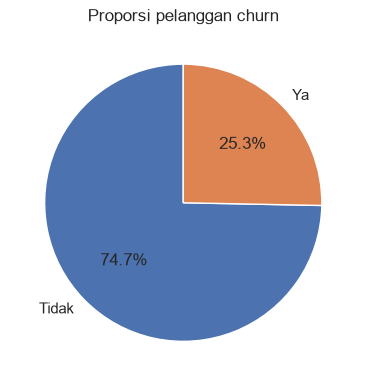

In [7]:
print("Jumlah baris, kolom:", df_churn.shape)
df_churn.info()
display(df_churn.head())

jumlah = df_churn["churn"].value_counts()
print(pd.DataFrame({"jumlah": jumlah, "persen": (jumlah / len(df_churn) * 100).round(2)}))

plt.figure(figsize=(4.5, 4.5))
plt.pie(jumlah, labels=jumlah.index, autopct="%.1f%%", colors=["#4c72b0", "#dd8452"], startangle=90)
plt.title("Proporsi pelanggan churn")
plt.show()

✍️ **Jawaban:**

Kelas **tidak seimbang**: churn = Ya hanya 25.3% (767 dari 3030 baris). Model yang selalu menebak
"Tidak" saja sudah mendapat accuracy ±74.7%, padahal tidak menemukan satu pun pelanggan churn. Karena itu
yang diperhatikan adalah **recall** kelas churn (berapa banyak pelanggan churn yang tertangkap), **precision**, **F1**,
dan **ROC-AUC**.

**b.** Lakukan *data cleaning* dan simpan hasilnya di `df1`:
1. Tampilkan jumlah baris duplikat, lalu hapus.
2. Hapus kolom `customer_id`.
3. Seragamkan `kota` (hapus spasi, huruf kapital di awal kata, `Bdg` → `Bandung`), lalu tampilkan `value_counts()`.
4. Ubah `umur` yang mustahil (< 17 atau > 90) menjadi `NaN`.
5. Ubah `churn` menjadi biner (Ya = 1, Tidak = 0).
6. Tampilkan jumlah missing value per kolom. **Jangan isi** missing value di sini (akan diisi di dalam `Pipeline`).

✍️ Mengapa pengisian missing value sebaiknya dilakukan di dalam `Pipeline` setelah split, bukan sebelum split?

*Clean the data into df1: drop duplicates, drop customer_id, standardize kota, set impossible ages to NaN, encode
churn as 1/0, and show missing values per column (do not impute yet).
✍️ Why should imputation happen inside the Pipeline after the split?*

In [10]:
df1 = df_churn.copy()
print("Duplikat:", df1.duplicated().sum())
df1 = df1.drop_duplicates().drop(columns="customer_id")

df1["kota"] = df1["kota"].str.strip().str.title().replace({"Bdg": "Bandung"})
print(df1["kota"].value_counts(), "\n")

umur_salah = (df1["umur"] < 17) | (df1["umur"] > 90)
print("Umur mustahil:", umur_salah.sum())
df1.loc[umur_salah, "umur"] = np.nan

df1["churn"] = df1["churn"].map({"Ya": 1, "Tidak": 0})
print("\nMissing value per kolom:")
print(df1.isna().sum())
print("\nUkuran df1:", df1.shape)

Duplikat: 30
kota
Surabaya    794
Jakarta     749
Medan       737
Bandung     720
Name: count, dtype: int64 

Umur mustahil: 8

Missing value per kolom:
gender                 0
umur                  33
kota                   0
paket                  0
kontrak                0
lama_berlangganan      0
biaya_bulanan         40
kecepatan_mbps         0
gangguan_per_bulan     0
tiket_komplain         0
metode_bayar          30
churn                  0
dtype: int64

Ukuran df1: (3000, 12)


✍️ **Jawaban:**

Terdapat 30 baris duplikat dan 8 umur mustahil; setelah dibersihkan `df1` berisi 3000 baris. Kota kini
hanya 4 nilai. Missing value tersisa di `umur` (33), `biaya_bulanan` (40), dan `metode_bayar` (30).

Median/modus untuk mengisi NaN adalah **statistik dari data**. Jika dihitung dari seluruh data sebelum split, informasi
dari data test ikut masuk ke proses latih (**data leakage**) sehingga skor test terlalu optimis. Di dalam `Pipeline`,
`SimpleImputer` hanya di-*fit* pada data train (dan pada fold train saat cross-validation).

**c.** Eksplorasi faktor churn:
1. Buat 1 figure 1×3: **tingkat churn (%) per `kontrak`** (bar), **tingkat churn (%) per `metode_bayar`** (bar), dan
   **boxplot `lama_berlangganan` per kelas churn**.
2. Tampilkan korelasi setiap kolom numerik dengan `churn`, diurutkan.

✍️ Sebutkan 3 temuan terpenting.

*Plot the churn rate per contract type and per payment method, and a boxplot of tenure per churn class (1×3 figure).
Show the correlation of each numeric column with churn. ✍️ Write the 3 most important findings.*

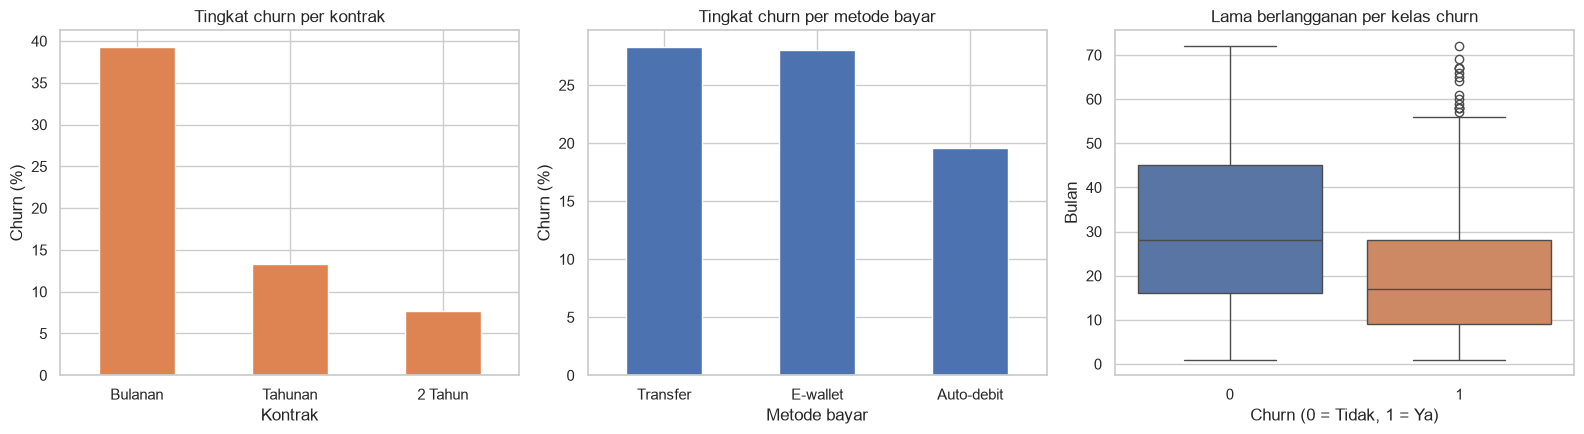

kontrak
Bulanan    39.3
Tahunan    13.3
2 Tahun     7.7
Name: churn, dtype: float64 

metode_bayar
Transfer      28.3
E-wallet      28.0
Auto-debit    19.6
Name: churn, dtype: float64 

lama_berlangganan    -0.295
umur                  0.011
kecepatan_mbps        0.061
biaya_bulanan         0.072
gangguan_per_bulan    0.182
tiket_komplain        0.199
Name: churn, dtype: float64


In [13]:
rate_kontrak = (df1.groupby("kontrak")["churn"].mean() * 100).sort_values(ascending=False)
rate_bayar = (df1.groupby("metode_bayar")["churn"].mean() * 100).sort_values(ascending=False)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
rate_kontrak.plot.bar(ax=ax[0], color="#dd8452", rot=0)
ax[0].set(title="Tingkat churn per kontrak", xlabel="Kontrak", ylabel="Churn (%)")
rate_bayar.plot.bar(ax=ax[1], color="#4c72b0", rot=0)
ax[1].set(title="Tingkat churn per metode bayar", xlabel="Metode bayar", ylabel="Churn (%)")
sns.boxplot(data=df1, x="churn", y="lama_berlangganan", hue="churn", ax=ax[2], legend=False)
ax[2].set(title="Lama berlangganan per kelas churn", xlabel="Churn (0 = Tidak, 1 = Ya)", ylabel="Bulan")
plt.tight_layout()
plt.show()

kor_churn = df1.select_dtypes("number").corr()["churn"].drop("churn").sort_values()
print(rate_kontrak.round(1), "\n")
print(rate_bayar.round(1), "\n")
print(kor_churn.round(3))

✍️ **Jawaban:**

1. **Kontrak** adalah pembeda terkuat: churn pelanggan Bulanan 39.3%, jauh di atas Tahunan
   (13.3%) dan 2 Tahun (7.7%).
2. **Lama berlangganan** berkorelasi negatif dengan churn (r = -0.295): pelanggan baru paling mudah pergi,
   terlihat dari median lama berlangganan yang lebih rendah pada kelas churn di boxplot.
3. **Kualitas layanan**: `tiket_komplain` (r = 0.199) dan `gangguan_per_bulan` (r = 0.182)
   berkorelasi positif. Pembayaran **Auto-debit** memiliki churn terendah (19.6% vs 28.3%
   pada Transfer).

**d.** Siapkan data untuk model:
1. Pisahkan `X` (semua kolom kecuali `churn`) dan `y`. Bagi **80:20** dengan `stratify=y` dan `random_state=42`.
   Tampilkan ukuran dan proporsi churn di train dan test.
2. Buat daftar `num_cols` dan `cat_cols`.
3. Buat fungsi `buat_preprocessor(scale=True)` yang mengembalikan `ColumnTransformer` **baru**: numerik →
   `SimpleImputer(median)` (+ `StandardScaler` jika `scale=True`); kategorikal → `SimpleImputer(most_frequent)` +
   `OneHotEncoder(handle_unknown="ignore")`.

*Split 80:20 with stratify, list numeric and categorical columns, and write buat_preprocessor(scale=True) that returns
a new ColumnTransformer (median imputer + optional scaler for numeric; mode imputer + one-hot for categorical).*

In [16]:
X = df1.drop(columns="churn")
y = df1["churn"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("train:", X_train.shape, "| test:", X_test.shape)
print(f"proporsi churn  train = {y_train.mean():.3f} | test = {y_test.mean():.3f}")

num_cols = X.select_dtypes("number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print("numerik   :", num_cols)
print("kategorik :", cat_cols)


def buat_preprocessor(scale=True):
    num_steps = [("imp", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("sc", StandardScaler()))
    cat_steps = [("imp", SimpleImputer(strategy="most_frequent")),
                 ("ohe", OneHotEncoder(handle_unknown="ignore"))]
    return ColumnTransformer([("num", Pipeline(num_steps), num_cols),
                              ("cat", Pipeline(cat_steps), cat_cols)],
                             verbose_feature_names_out=False)

train: (2400, 11) | test: (600, 11)
proporsi churn  train = 0.253 | test = 0.253
numerik   : ['umur', 'lama_berlangganan', 'biaya_bulanan', 'kecepatan_mbps', 'gangguan_per_bulan', 'tiket_komplain']
kategorik : ['gender', 'kota', 'paket', 'kontrak', 'metode_bayar']


**e.** Latih tiga model dalam `Pipeline` (`buat_preprocessor()` + model) dan simpan di dict `models_1`:
- `LogisticRegression(max_iter=1000)`
- `KNeighborsClassifier(n_neighbors=15)`
- `RandomForestClassifier(n_estimators=300, random_state=42)` (preprocessor tanpa scaling)

Hitung **accuracy, precision, recall, F1, dan ROC-AUC** pada data test, simpan dalam DataFrame `hasil_1`
(index = nama model). ✍️ Model mana yang paling cocok untuk tim retensi dan mengapa?

*Train Logistic Regression, KNN (k=15), and Random Forest pipelines, store them in models_1, and build hasil_1 with
accuracy, precision, recall, F1, and ROC-AUC on the test set. ✍️ Which model suits the retention team best, and why?*

In [18]:
models_1 = {
    "Logistic Regression": Pipeline([("prep", buat_preprocessor()),
                                     ("model", LogisticRegression(max_iter=1000))]),
    "KNN (k=15)": Pipeline([("prep", buat_preprocessor()),
                            ("model", KNeighborsClassifier(n_neighbors=15))]),
    "Random Forest": Pipeline([("prep", buat_preprocessor(scale=False)),
                               ("model", RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1))]),
}
rows = []
for nama, model in models_1.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    rows.append({"model": nama,
                 "accuracy": accuracy_score(y_test, pred),
                 "precision": precision_score(y_test, pred),
                 "recall": recall_score(y_test, pred),
                 "f1": f1_score(y_test, pred),
                 "roc_auc": roc_auc_score(y_test, proba)})
hasil_1 = pd.DataFrame(rows).set_index("model").round(4)
display(hasil_1)

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Logistic Regression,0.7883,0.6582,0.3421,0.4502,0.8039
KNN (k=15),0.7750,0.6604,0.2303,0.3415,0.7491
Random Forest,0.7650,0.5696,0.2961,0.3896,0.7755


✍️ **Jawaban:**

Hasil test — Logistic Regression: accuracy 0.7883, recall 0.3421, F1 0.4502, AUC 0.8039; KNN (k=15): accuracy 0.7750, recall 0.2303, F1 0.3415, AUC 0.7491; Random Forest: accuracy 0.7650, recall 0.2961, F1 0.3896, AUC 0.7755. **Logistic Regression** memiliki F1 tertinggi sekaligus ROC-AUC tertinggi. Saya memilih **Logistic Regression**: selain skornya terbaik, koefisiennya bisa dijelaskan ke tim bisnis dan peluang churn-nya bisa dipakai untuk mengatur threshold. Hubungan fitur dengan churn pada data ini cenderung monoton (makin lama berlangganan makin kecil peluang churn, makin banyak komplain makin besar), sehingga model linier sudah cukup; Random Forest dan KNN tidak mendapat keuntungan dari fleksibilitasnya.

Untuk tim retensi, kesalahan yang paling mahal adalah **false negative** (pelanggan yang akan churn tidak terdeteksi),
jadi recall dan F1 lebih penting daripada accuracy. Selisih accuracy antar model kecil, tetapi ROC-AUC dan F1
menunjukkan seberapa baik model memisahkan kedua kelas.

**f.** 1. Tampilkan **confusion matrix** Regresi Logistik dalam bentuk heatmap (label `Tidak`/`Ya`).
2. Turunkan **threshold** Regresi Logistik dari 0.5 menjadi 0.3 (`predict_proba(X_test)[:, 1] >= 0.3`).
   Bandingkan precision, recall, F1, dan jumlah pelanggan yang ditandai churn untuk kedua threshold dalam DataFrame
   `hasil_threshold`.

✍️ Jelaskan *trade-off* yang terjadi dan threshold mana yang Anda sarankan.

*Plot the Logistic Regression confusion matrix as a heatmap, then compare thresholds 0.5 and 0.3 (precision, recall,
F1, number of flagged customers) in hasil_threshold. ✍️ Explain the trade-off and recommend a threshold.*

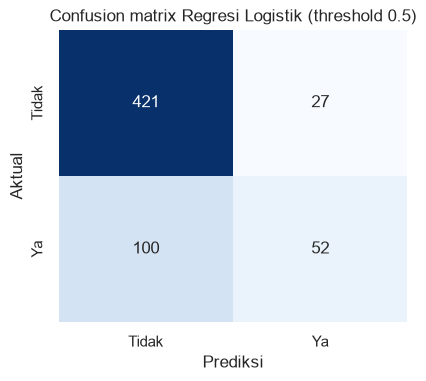

,precision,recall,f1,ditandai_churn
threshold,,,,
0.5,0.6582,0.3421,0.4502,79
0.3,0.5135,0.6250,0.5638,185


In [21]:
lr_churn = models_1["Logistic Regression"]
proba_lr = lr_churn.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, (proba_lr >= 0.5).astype(int))
plt.figure(figsize=(4.5, 3.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Tidak", "Ya"], yticklabels=["Tidak", "Ya"])
plt.title("Confusion matrix Regresi Logistik (threshold 0.5)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.show()

rows = []
for t in [0.5, 0.3]:
    pred_t = (proba_lr >= t).astype(int)
    rows.append({"threshold": t, "precision": precision_score(y_test, pred_t),
                 "recall": recall_score(y_test, pred_t), "f1": f1_score(y_test, pred_t),
                 "ditandai_churn": int(pred_t.sum())})
hasil_threshold = pd.DataFrame(rows).set_index("threshold").round(4)
display(hasil_threshold)

✍️ **Jawaban:**

Pada threshold 0.5, dari 152 pelanggan churn di data test, model menangkap 52 (TP) dan melewatkan 100 (FN);
ada 27 pelanggan setia yang salah ditandai (FP).

Menurunkan threshold ke 0.3 membuat model lebih mudah menyebut "churn": recall naik dari 0.342 ke 0.625,
tetapi precision turun dari 0.658 ke 0.513 dan jumlah pelanggan yang ditandai naik dari 79 ke
185. Karena biaya kehilangan pelanggan biasanya jauh lebih besar daripada biaya menghubungi pelanggan yang sebenarnya setia, threshold **0.3** lebih cocok untuk tim retensi (F1 0.450 → 0.564).

**g.** Interpretasi model:
1. Ambil nama fitur hasil preprocessing (`get_feature_names_out()`), lalu tampilkan **5 koefisien Regresi Logistik**
   dengan nilai absolut terbesar.
2. Tampilkan **5 feature importance** teratas Random Forest.
3. Buat 1 figure 1×2 berisi kedua bar chart tersebut.

✍️ Jelaskan arti tanda koefisien dan apakah kedua model sepakat tentang fitur terpenting.

*Show the 5 Logistic Regression coefficients with the largest absolute values and the top 5 Random Forest feature
importances, as two bar charts in one 1×2 figure. ✍️ Explain the sign of the coefficients and whether both models agree.*

kontrak_Bulanan      0.951
kontrak_2 Tahun     -0.773
lama_berlangganan   -0.593
biaya_bulanan        0.511
tiket_komplain       0.463
dtype: float64 

lama_berlangganan     0.188
biaya_bulanan         0.176
umur                  0.152
tiket_komplain        0.083
gangguan_per_bulan    0.080
dtype: float64


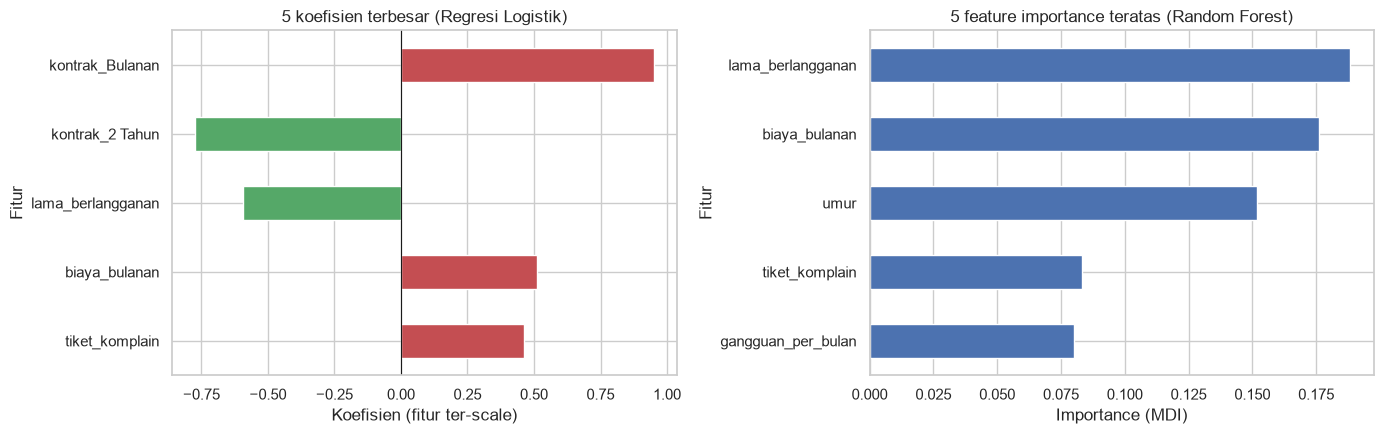

In [24]:
fitur = lr_churn.named_steps["prep"].get_feature_names_out()
koef = pd.Series(lr_churn.named_steps["model"].coef_[0], index=fitur)
top_koef = koef.reindex(koef.abs().sort_values(ascending=False).index).head(5)

rf_churn = models_1["Random Forest"]
imp = pd.Series(rf_churn.named_steps["model"].feature_importances_,
                index=rf_churn.named_steps["prep"].get_feature_names_out())
top_imp = imp.sort_values(ascending=False).head(5)
print(top_koef.round(3), "\n")
print(top_imp.round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
top_koef[::-1].plot.barh(ax=ax[0], color=np.where(top_koef[::-1] > 0, "#c44e52", "#55a868"))
ax[0].axvline(0, color="k", lw=0.8)
ax[0].set(title="5 koefisien terbesar (Regresi Logistik)", xlabel="Koefisien (fitur ter-scale)", ylabel="Fitur")
top_imp[::-1].plot.barh(ax=ax[1], color="#4c72b0")
ax[1].set(title="5 feature importance teratas (Random Forest)", xlabel="Importance (MDI)", ylabel="Fitur")
plt.tight_layout()
plt.show()

✍️ **Jawaban:**

Koefisien Regresi Logistik dihitung pada fitur yang sudah di-scale (numerik) atau one-hot (kategorikal). **Positif**
berarti menaikkan peluang churn, **negatif** menurunkan. Lima koefisien terbesar: `kontrak_Bulanan` (+0.951), `kontrak_2 Tahun` (-0.773), `lama_berlangganan` (-0.593), `biaya_bulanan` (+0.511), `tiket_komplain` (+0.463).
Contohnya, `kontrak_Bulanan` = +0.951, artinya pelanggan berkontrak bulanan jauh lebih berisiko churn dibanding kontrak lain.

Lima fitur terpenting Random Forest: `lama_berlangganan`, `biaya_bulanan`, `umur`, `tiket_komplain`, `gangguan_per_bulan`. Kedua model sepakat bahwa `lama_berlangganan`, `biaya_bulanan`, `tiket_komplain` termasuk fitur terpenting. Perbedaannya,
importance RF tidak punya tanda (hanya seberapa sering dan seberapa baik fitur dipakai membagi data) dan cenderung
lebih tinggi untuk fitur numerik kontinu dengan banyak nilai unik. Contohnya `umur`: masuk 5 besar importance RF, padahal tidak masuk 5 besar koefisien Regresi Logistik dan tingkat churn hampir sama di semua umur. Ini bias MDI terhadap fitur kontinu, bukan bukti bahwa umur memengaruhi churn.

**h.** **(BONUS)** Latih ulang Regresi Logistik dengan `class_weight="balanced"`. Bandingkan precision, recall, dan F1-nya
dengan Regresi Logistik biasa. ✍️ Apa efek `class_weight="balanced"`?

*(BONUS) Retrain Logistic Regression with class_weight="balanced" and compare precision, recall, and F1 with the
default model. ✍️ What does class_weight="balanced" do?*

In [27]:
lr_bal = Pipeline([("prep", buat_preprocessor()),
                   ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))]).fit(X_train, y_train)
banding = {}
for nama, m in [("LogReg biasa", lr_churn), ("LogReg balanced", lr_bal)]:
    p = m.predict(X_test)
    banding[nama] = {"precision": precision_score(y_test, p), "recall": recall_score(y_test, p),
                     "f1": f1_score(y_test, p)}
hasil_balanced = pd.DataFrame(banding).T.round(4)
display(hasil_balanced)

,precision,recall,f1
LogReg biasa,0.6582,0.3421,0.4502
LogReg balanced,0.4809,0.7434,0.5840


✍️ **Jawaban:**

`class_weight="balanced"` memberi bobot kesalahan pada kelas minoritas sebanding dengan kelangkaannya
(bobot = n_sampel / (n_kelas × n_sampel_kelas)). Model menjadi lebih "berani" menebak churn: recall naik dari
0.342 ke 0.743, precision turun dari 0.658 ke 0.481, dan F1 berubah dari
0.450 ke 0.584. Efeknya mirip menurunkan threshold, tetapi terjadi saat training.

---
## SOAL 2 — Klasifikasi Wine dengan KNN dan ANN (25 poin)

Dataset bawaan scikit-learn **wine** berisi 13 hasil analisis kimia dari 178 wine yang berasal dari 3 kultivar
(`class_0`, `class_1`, `class_2`). Skala fiturnya sangat berbeda, misalnya `proline` ratusan sampai ribuan,
sedangkan `hue` di bawah 2.

*The built-in wine dataset has 13 chemical measurements of 178 wines from 3 cultivars. Feature scales differ a lot.*

### Setup dataset (jangan diubah)

In [30]:
from sklearn.datasets import load_wine
wine = load_wine(as_frame=True)

**a.** Buat DataFrame `df_wine` dari `wine.frame`, tambahkan kolom `kelas` berisi nama kelas (`wine.target_names`).
Tampilkan ukuran data, jumlah data per kelas, serta nilai **min, max, mean, dan std** setiap fitur.
✍️ Fitur mana yang skalanya paling besar dan paling kecil? Apa akibatnya untuk KNN?

*Create df_wine with a kelas column of class names. Show the shape, class counts, and min/max/mean/std of each feature.
✍️ Which features have the largest and smallest scale, and what does that mean for KNN?*

In [32]:
df_wine = wine.frame.copy()
df_wine["kelas"] = df_wine["target"].map(dict(enumerate(wine.target_names)))
print("Ukuran:", df_wine.shape)
print(df_wine["kelas"].value_counts().sort_index(), "\n")
skala = df_wine[wine.feature_names].describe().T[["min", "max", "mean", "std"]].sort_values("std", ascending=False)
display(skala.round(3))

Ukuran: (178, 15)
kelas
class_0    59
class_1    71
class_2    48
Name: count, dtype: int64 



,min,max,mean,std
proline,278.00,1680.00,746.893,314.907
magnesium,70.00,162.00,99.742,14.282
alcalinity_of_ash,10.60,30.00,19.495,3.340
color_intensity,1.28,13.00,5.058,2.318
malic_acid,0.74,5.80,2.336,1.117
flavanoids,0.34,5.08,2.029,0.999
alcohol,11.03,14.83,13.001,0.812
od280/od315_of_diluted_wines,1.27,4.00,2.612,0.710
total_phenols,0.98,3.88,2.295,0.626
proanthocyanins,0.41,3.58,1.591,0.572


✍️ **Jawaban:**

`proline` memiliki skala terbesar (rentang 278–1680, std 314.9), sedangkan `nonflavanoid_phenols` paling
kecil (std 0.124). KNN menghitung **jarak Euclidean**, sehingga tanpa scaling jarak hampir seluruhnya
ditentukan oleh `proline` (dan `magnesium`); 11 fitur lain praktis diabaikan.

**b.** Pisahkan `X_w` (13 fitur) dan `y_w` (`target`), lalu bagi **75:25** dengan `stratify` dan `random_state=42`.
Tampilkan ukuran train dan test.

*Split X_w and y_w 75:25 with stratify and random_state=42, and show the shapes.*

In [35]:
X_w = df_wine[wine.feature_names]
y_w = df_wine["target"]
Xw_train, Xw_test, yw_train, yw_test = train_test_split(X_w, y_w, test_size=0.25, stratify=y_w, random_state=42)
print("train:", Xw_train.shape, "| test:", Xw_test.shape)

train: (133, 13) | test: (45, 13)


**c.** Latih `KNeighborsClassifier(n_neighbors=5)` **tanpa scaling** dan **dengan** `StandardScaler` (dalam `Pipeline`).
Tampilkan accuracy test keduanya. ✍️ Jelaskan perbedaannya.

*Train KNN (k=5) without scaling and with StandardScaler in a Pipeline, and show both test accuracies. ✍️ Explain.*

In [37]:
knn_raw = KNeighborsClassifier(n_neighbors=5).fit(Xw_train, yw_train)
knn_sc = Pipeline([("sc", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=5))]).fit(Xw_train, yw_train)
acc_knn_raw = accuracy_score(yw_test, knn_raw.predict(Xw_test))
acc_knn_sc = accuracy_score(yw_test, knn_sc.predict(Xw_test))
print(f"KNN tanpa scaling : {acc_knn_raw:.4f}")
print(f"KNN dengan scaling: {acc_knn_sc:.4f}")

KNN tanpa scaling : 0.7778
KNN dengan scaling: 0.9333


✍️ **Jawaban:**

Accuracy naik dari **0.7778** menjadi **0.9333** setelah scaling. Tanpa scaling, tetangga
"terdekat" hanyalah wine dengan kadar `proline` yang mirip. Setelah `StandardScaler` (mean 0, std 1), setiap fitur
berkontribusi seimbang pada jarak sehingga fitur pembeda lain (`flavanoids`, `color_intensity`, `alcohol`) ikut dipakai.

**d.** Cari *k* terbaik untuk KNN dengan scaling: untuk *k* = 1, 3, 5, …, 29 hitung rata-rata accuracy
**5-fold `StratifiedKFold`** (`shuffle=True`, `random_state=42`) **pada data train**. Simpan di Series `cv_k`,
buat line plot *k* vs accuracy CV, lalu latih ulang model dengan *k* terbaik (`best_k`) dan tampilkan accuracy test.
Jika beberapa *k* memiliki skor CV yang sama, pilih *k* **terbesar** (model lebih stabil).
✍️ Mengapa *k* dipilih dengan CV di data train, bukan dengan data test?

*For k = 1, 3, …, 29, compute the mean 5-fold stratified CV accuracy on the training data (with scaling), plot it,
retrain with the best k (largest k on ties), and show the test accuracy. ✍️ Why choose k with CV on train instead of the test set?*

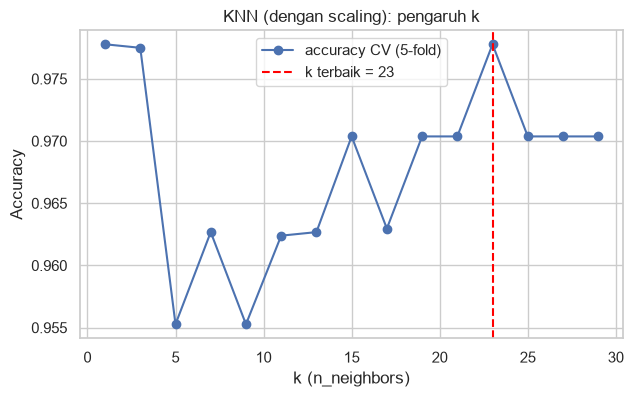

best_k = 23 | CV = 0.9778 | test = 1.0


In [40]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
ks = range(1, 30, 2)
cv_k = pd.Series({k: cross_val_score(Pipeline([("sc", StandardScaler()),
                                               ("knn", KNeighborsClassifier(n_neighbors=k))]),
                                     Xw_train, yw_train, cv=skf).mean() for k in ks})
best_k = int(cv_k[np.isclose(cv_k, cv_k.max())].index.max())   # seri → k terbesar

plt.figure(figsize=(7, 4))
plt.plot(cv_k.index, cv_k.values, marker="o", label="accuracy CV (5-fold)")
plt.axvline(best_k, color="red", ls="--", label=f"k terbaik = {best_k}")
plt.title("KNN (dengan scaling): pengaruh k")
plt.xlabel("k (n_neighbors)")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

knn_best = Pipeline([("sc", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=best_k))]).fit(Xw_train, yw_train)
acc_knn_best = accuracy_score(yw_test, knn_best.predict(Xw_test))
print("best_k =", best_k, "| CV =", round(cv_k.max(), 4), "| test =", round(acc_knn_best, 4))

✍️ **Jawaban:**

*k* terbaik = **23** dengan accuracy CV 0.9778 dan accuracy test 1.0000. Skor *k* = 1 sama tinggi (0.9778), tetapi *k* = 1 hanya mengandalkan satu tetangga sehingga sangat sensitif terhadap noise (variance tinggi); karena itu saat seri dipilih *k* yang lebih besar. *k* yang terlalu besar membuat batas keputusan terlalu halus (bias tinggi).

Jika *k* dipilih berdasarkan skor test, data test ikut menentukan model sehingga skornya tidak lagi menggambarkan
performa pada data baru. CV di data train memberi estimasi yang jujur, dan data test hanya dipakai sekali di akhir.

**e.** Buat **ANN** dengan `Pipeline` `StandardScaler` → `MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=2000,
random_state=42)` dan simpan di `ann_wine`. Tampilkan accuracy train dan test, jumlah epoch (`n_iter_`), lalu plot
**kurva loss** (`loss_curve_`).

*Build an ANN pipeline (StandardScaler → MLPClassifier((32, 16), max_iter=2000, random_state=42)) as ann_wine.
Show train/test accuracy and the number of epochs, and plot the loss curve.*

train = 1.0000 | test = 0.9556 | epoch = 284


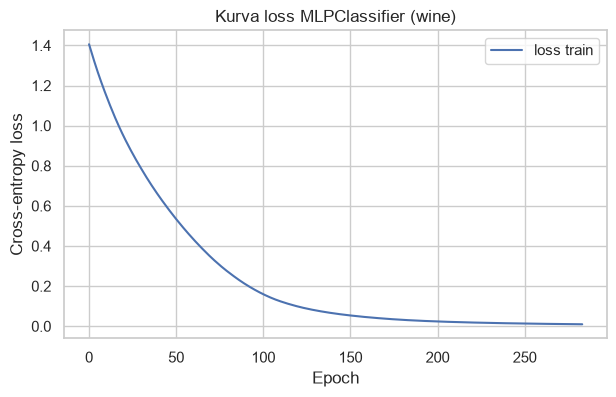

In [43]:
ann_wine = Pipeline([("sc", StandardScaler()),
                     ("mlp", MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=2000, random_state=42))])
ann_wine.fit(Xw_train, yw_train)
mlp = ann_wine.named_steps["mlp"]
acc_ann_train = ann_wine.score(Xw_train, yw_train)
acc_ann_test = ann_wine.score(Xw_test, yw_test)
print(f"train = {acc_ann_train:.4f} | test = {acc_ann_test:.4f} | epoch = {mlp.n_iter_}")

plt.figure(figsize=(7, 4))
plt.plot(mlp.loss_curve_, label="loss train")
plt.title("Kurva loss MLPClassifier (wine)")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.legend()
plt.show()

**f.** Lakukan `GridSearchCV` (cv = `skf`, scoring accuracy) pada pipeline ANN dengan grid:
`hidden_layer_sizes` ∈ {(16,), (32, 16), (64, 32)}, `alpha` ∈ {0.0001, 0.01, 1}, `learning_rate_init` ∈ {0.001, 0.01}.
Tampilkan parameter terbaik, skor CV terbaik, dan accuracy test model terbaik (`ann_best`).
✍️ Apa fungsi parameter `alpha`?

*Run GridSearchCV on the ANN pipeline with the given grid. Show the best parameters, best CV score, and the test
accuracy of the best model (ann_best). ✍️ What does alpha do?*

In [45]:
grid_ann = GridSearchCV(
    Pipeline([("sc", StandardScaler()), ("mlp", MLPClassifier(max_iter=2000, random_state=42))]),
    param_grid={"mlp__hidden_layer_sizes": [(16,), (32, 16), (64, 32)],
                "mlp__alpha": [0.0001, 0.01, 1],
                "mlp__learning_rate_init": [0.001, 0.01]},
    cv=skf, scoring="accuracy", n_jobs=-1)
grid_ann.fit(Xw_train, yw_train)
ann_best = grid_ann.best_estimator_
acc_ann_best = accuracy_score(yw_test, ann_best.predict(Xw_test))
print("parameter terbaik:", grid_ann.best_params_)
print(f"CV terbaik = {grid_ann.best_score_:.4f} | test = {acc_ann_best:.4f}")

parameter terbaik: {'mlp__alpha': 1, 'mlp__hidden_layer_sizes': (32, 16), 'mlp__learning_rate_init': 0.001}
CV terbaik = 0.9926 | test = 0.9778


✍️ **Jawaban:**

Parameter terbaik: `{'mlp__alpha': 1, 'mlp__hidden_layer_sizes': (32, 16), 'mlp__learning_rate_init': 0.001}` dengan accuracy CV 0.9926 dan accuracy test 0.9778.
`alpha` adalah kekuatan **regularisasi L2**: makin besar, bobot jaringan makin ditekan agar tidak terlalu besar
sehingga model lebih sederhana dan tidak mudah overfit. Pada dataset kecil seperti wine (133 data latih), regularisasi
membantu generalisasi.

**g.** Buat DataFrame `hasil_2` berisi accuracy test untuk: KNN tanpa scaling, KNN dengan scaling (k=5), KNN *k* terbaik,
ANN (32, 16), dan ANN hasil GridSearch. Tampilkan juga `classification_report` model terbaik.
✍️ Model mana yang Anda pilih? Mengapa scaling penting untuk KNN **dan** ANN?

*Build hasil_2 with the test accuracy of the five models and show the classification report of the best one.
✍️ Which model do you choose? Why is scaling important for both KNN and ANN?*

In [48]:
hasil_2 = pd.Series({"KNN tanpa scaling": acc_knn_raw, "KNN scaling (k=5)": acc_knn_sc,
                     f"KNN scaling (k={best_k})": acc_knn_best, "ANN (32, 16)": acc_ann_test,
                     "ANN GridSearch": acc_ann_best}, name="accuracy_test").sort_values(ascending=False).round(4)
display(hasil_2.to_frame())
model_wine = {"KNN tanpa scaling": knn_raw, "KNN scaling (k=5)": knn_sc, f"KNN scaling (k={best_k})": knn_best,
              "ANN (32, 16)": ann_wine, "ANN GridSearch": ann_best}
terbaik_2 = hasil_2.index[0]
print("Model terbaik:", terbaik_2)
print(classification_report(yw_test, model_wine[terbaik_2].predict(Xw_test), target_names=wine.target_names, digits=3))

,accuracy_test
KNN scaling (k=23),1.0000
ANN GridSearch,0.9778
"ANN (32, 16)",0.9556
KNN scaling (k=5),0.9333
KNN tanpa scaling,0.7778


Model terbaik: KNN scaling (k=23)
              precision    recall  f1-score   support

     class_0      1.000     1.000     1.000        15
     class_1      1.000     1.000     1.000        18
     class_2      1.000     1.000     1.000        12

    accuracy                          1.000        45
   macro avg      1.000     1.000     1.000        45
weighted avg      1.000     1.000     1.000        45



✍️ **Jawaban:**

Accuracy test: KNN scaling (k=23) 1.0000, ANN GridSearch 0.9778, ANN (32, 16) 0.9556, KNN scaling (k=5) 0.9333, KNN tanpa scaling 0.7778. Model terbaik **KNN scaling (k=23)**. KNN tanpa scaling jauh tertinggal (0.7778). Namun selisih KNN scaling (k=23) dengan ANN GridSearch hanya 1 dari 45 data test, jadi keduanya praktis setara; skor CV di data train lebih bisa dipegang untuk membandingkan keduanya.

KNN memakai jarak sehingga fitur berskala besar mendominasi. ANN dilatih dengan *gradient descent*: jika skala input
berbeda jauh, gradien untuk tiap bobot juga berbeda jauh sehingga training lambat atau tidak stabil (konvergensi buruk).
Karena itu keduanya wajib memakai `StandardScaler`, sedangkan model berbasis pohon tidak memerlukannya.

**h.** **(BONUS)** Dengan dua fitur saja, `alcohol` dan `proline`, gambarkan **decision boundary** KNN (*k* = 15) tanpa scaling
dan dengan scaling dalam 1 figure 1×2 (`DecisionBoundaryDisplay`). ✍️ Apa yang terlihat?

*(BONUS) Using only alcohol and proline, draw the KNN (k=15) decision boundary without and with scaling (1×2 figure).
✍️ What do you see?*

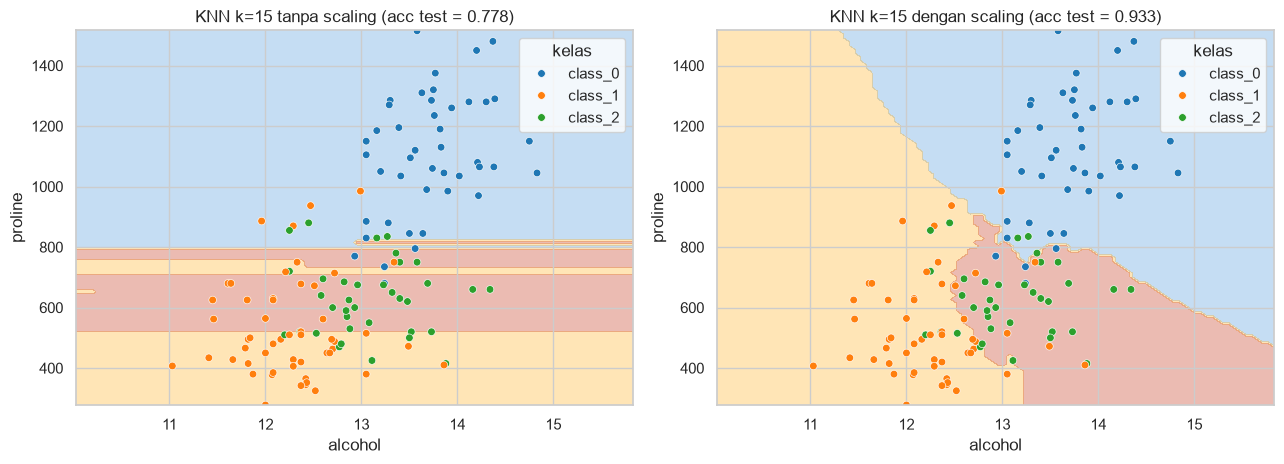

In [51]:
dua = ["alcohol", "proline"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for a, (judul, model) in zip(ax, [("tanpa scaling", KNeighborsClassifier(n_neighbors=15)),
                                  ("dengan scaling", Pipeline([("sc", StandardScaler()),
                                                               ("knn", KNeighborsClassifier(n_neighbors=15))]))]):
    model.fit(Xw_train[dua], yw_train)
    DecisionBoundaryDisplay.from_estimator(model, Xw_train[dua], response_method="predict", alpha=0.3, ax=a)
    sns.scatterplot(data=Xw_train[dua].assign(kelas=wine.target_names[yw_train]), x="alcohol", y="proline",
                    hue="kelas", palette="tab10", ax=a, s=30)
    a.set(title=f"KNN k=15 {judul} (acc test = {model.score(Xw_test[dua], yw_test):.3f})",
          xlabel="alcohol", ylabel="proline")
plt.tight_layout()
plt.show()

✍️ **Jawaban:**

Tanpa scaling, batas keputusan hampir **horizontal**: hanya `proline` yang menentukan kelas karena selisih `alcohol`
(±1) tidak berarti dibanding selisih `proline` (ratusan). Setelah scaling, batasnya memanfaatkan kedua sumbu sehingga
kelas `class_1` (alcohol rendah) bisa dipisahkan dari `class_2`.

---
## SOAL 3 — Diagnosis Kanker Payudara dengan Ensemble (25 poin)

Dataset bawaan **breast cancer** berisi 30 fitur hasil citra sel dari 569 pasien, dengan diagnosis *malignant*
(ganas) atau *benign* (jinak). Pada dataset ini `target = 0` berarti **malignant**. Kesalahan paling berbahaya adalah
pasien ganas yang diprediksi jinak (**false negative**).

*The built-in breast cancer dataset has 30 features from 569 patients. target = 0 means malignant. The most dangerous
error is a malignant tumour predicted as benign (false negative).*

### Setup dataset (jangan diubah)

In [54]:
from sklearn.datasets import load_breast_cancer
bc = load_breast_cancer(as_frame=True)

**a.** Buat `df_bc` dari `bc.frame`, lalu buat kolom `ganas` = 1 jika `target == 0` (malignant) dan 0 jika sebaliknya.
Tampilkan jumlah dan persentase setiap kelas `ganas`. ✍️ Mengapa kelas positif (1) sebaiknya adalah *malignant*?

*Create df_bc and a column ganas = 1 for malignant (target == 0). Show the count and percentage of each class.
✍️ Why should malignant be the positive class (1)?*

In [56]:
df_bc = bc.frame.copy()
df_bc["ganas"] = (df_bc["target"] == 0).astype(int)
jumlah_bc = df_bc["ganas"].value_counts()
print(pd.DataFrame({"jumlah": jumlah_bc, "persen": (jumlah_bc / len(df_bc) * 100).round(2)}))

       jumlah  persen
ganas                
0         357   62.74
1         212   37.26


✍️ **Jawaban:**

Ada 212 kasus ganas (37.3%) dan 357 jinak. `precision_score`, `recall_score`, dan
`f1_score` secara default menghitung untuk kelas **1**. Dengan malignant = 1, *recall* langsung berarti "berapa persen
pasien kanker yang terdeteksi", yaitu metrik yang paling penting secara medis.

**b.** Pisahkan `X_b` (30 fitur) dan `y_b` (`ganas`), bagi **80:20** dengan `stratify` dan `random_state=42`.
Buat fungsi `metrik(model)` yang mengembalikan dict **accuracy, precision, recall, dan F1** model pada data test.

*Split X_b and y_b 80:20 with stratify and random_state=42. Write metrik(model) that returns a dict of test accuracy,
precision, recall, and F1.*

In [59]:
X_b = df_bc[bc.feature_names]
y_b = df_bc["ganas"]
Xb_train, Xb_test, yb_train, yb_test = train_test_split(X_b, y_b, test_size=0.2, stratify=y_b, random_state=42)
print("train:", Xb_train.shape, "| test:", Xb_test.shape)


def metrik(model):
    pred = model.predict(Xb_test)
    return {"accuracy": accuracy_score(yb_test, pred), "precision": precision_score(yb_test, pred),
            "recall": recall_score(yb_test, pred), "f1": f1_score(yb_test, pred)}

train: (455, 30) | test: (114, 30)


**c.** Buat tiga **model dasar** dan simpan di list `base`:
- `("lr", Pipeline(StandardScaler, LogisticRegression(max_iter=1000)))`
- `("knn", Pipeline(StandardScaler, KNeighborsClassifier(n_neighbors=7)))`
- `("tree", DecisionTreeClassifier(max_depth=4, random_state=42))`

Untuk tiap model, hitung rata-rata **accuracy dan recall 5-fold CV** di data train (`cross_validate`, cv = `skf`),
simpan di DataFrame `cv_base`.

*Create the three base models in the list base and compute their mean 5-fold CV accuracy and recall on the training
data with cross_validate, stored in cv_base.*

In [61]:
base = [
    ("lr", Pipeline([("sc", StandardScaler()), ("m", LogisticRegression(max_iter=1000))])),
    ("knn", Pipeline([("sc", StandardScaler()), ("m", KNeighborsClassifier(n_neighbors=7))])),
    ("tree", DecisionTreeClassifier(max_depth=4, random_state=42)),
]
cv_base = pd.DataFrame({
    nama: {k: v.mean() for k, v in cross_validate(m, Xb_train, yb_train, cv=skf,
                                                  scoring=["accuracy", "recall"]).items() if k.startswith("test_")}
    for nama, m in base}).T.round(4)
display(cv_base)

,test_accuracy,test_recall
lr,0.9736,0.9529
knn,0.9692,0.9294
tree,0.9209,0.8647


**d.** Gabungkan ketiga model dasar dengan `VotingClassifier`, versi **hard** (`vote_hard`) dan **soft** (`vote_soft`).
Latih di data train dan tampilkan `metrik()` keduanya beserta ketiga model dasar dalam satu DataFrame `hasil_vote`.
✍️ Apa beda hard dan soft voting?

*Combine the base models with VotingClassifier (hard and soft), train them, and show metrik() for the two voting models
and the three base models in hasil_vote. ✍️ What is the difference between hard and soft voting?*

In [63]:
vote_hard = VotingClassifier(base, voting="hard").fit(Xb_train, yb_train)
vote_soft = VotingClassifier(base, voting="soft").fit(Xb_train, yb_train)
fitted_base = {nama: m.fit(Xb_train, yb_train) for nama, m in base}
hasil_vote = pd.DataFrame({**{nama: metrik(m) for nama, m in fitted_base.items()},
                           "Voting hard": metrik(vote_hard), "Voting soft": metrik(vote_soft)}).T.round(4)
display(hasil_vote)

,accuracy,precision,recall,f1
lr,0.9649,0.9750,0.9286,0.9512
knn,0.9561,0.9744,0.9048,0.9383
tree,0.9123,0.9444,0.8095,0.8718
Voting hard,0.9649,1.0000,0.9048,0.9500
Voting soft,0.9649,1.0000,0.9048,0.9500


✍️ **Jawaban:**

**Hard voting** mengambil label terbanyak dari ketiga model. **Soft voting** merata-ratakan `predict_proba` lalu
memilih kelas dengan peluang tertinggi, sehingga keyakinan model ikut diperhitungkan (model yang sangat yakin bisa
mengalahkan dua model yang ragu). Hasil test: Voting hard accuracy 0.9649 / recall 0.9048, Voting soft
accuracy 0.9649 / recall 0.9048, dibanding model dasar terbaik `lr` (accuracy 0.9649).

**e.** Bandingkan **Decision Tree tunggal** (`max_depth=None`, `random_state=42`) dengan ensemble berbasis pohon:
- `BaggingClassifier(DecisionTreeClassifier(), n_estimators=200, random_state=42)`
- `RandomForestClassifier(n_estimators=300, random_state=42)`
- `AdaBoostClassifier(n_estimators=200, random_state=42)`
- `GradientBoostingClassifier(random_state=42)`

Tampilkan accuracy **train** dan `metrik()` test dalam DataFrame `hasil_tree`. ✍️ Jelaskan perbedaan bagging dan
boosting berdasarkan hasilnya.

*Compare a single fully grown Decision Tree with Bagging, Random Forest, AdaBoost, and Gradient Boosting. Show the train
accuracy and the test metrics in hasil_tree. ✍️ Explain bagging vs boosting using the results.*

In [66]:
model_tree = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Bagging": BaggingClassifier(DecisionTreeClassifier(), n_estimators=200, random_state=42, n_jobs=-1),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    "AdaBoost": AdaBoostClassifier(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}
rows = {}
for nama, m in model_tree.items():
    m.fit(Xb_train, yb_train)
    rows[nama] = {"acc_train": m.score(Xb_train, yb_train), **metrik(m)}
hasil_tree = pd.DataFrame(rows).T.round(4)
display(hasil_tree)

,acc_train,accuracy,precision,recall,f1
Decision Tree,1.0,0.9298,0.9048,0.9048,0.9048
Bagging,1.0,0.9737,1.0000,0.9286,0.9630
Random Forest,1.0,0.9737,1.0000,0.9286,0.9630
AdaBoost,1.0,0.9737,1.0000,0.9286,0.9630
Gradient Boosting,1.0,0.9649,1.0000,0.9048,0.9500


✍️ **Jawaban:**

Decision Tree tunggal mencapai accuracy train 1.0000 tetapi test 0.9298 (overfit, variance tinggi).
**Bagging** dan **Random Forest** melatih banyak pohon secara paralel pada *bootstrap sample* lalu voting; rata-rata
banyak pohon menurunkan variance sehingga accuracy test naik menjadi 0.9737 dan 0.9737. Random Forest
juga mengacak subset fitur di tiap split sehingga pohon-pohonnya lebih beragam.
**Boosting** (AdaBoost 0.9737, Gradient Boosting 0.9649) melatih model lemah secara **berurutan**; setiap
model baru fokus pada kesalahan model sebelumnya sehingga yang diturunkan terutama **bias**.

**f.** Buat `StackingClassifier` dengan `estimators = base + [("rf", RandomForestClassifier(n_estimators=300,
random_state=42))]`, `final_estimator=LogisticRegression(max_iter=1000)`, dan `cv=5`. Tampilkan `metrik()`-nya.
✍️ Mengapa stacking melatih *meta-model* dari prediksi *out-of-fold*?

*Build a StackingClassifier (base models + Random Forest, final LogisticRegression, cv=5) and show its metrics.
✍️ Why does stacking train the meta-model on out-of-fold predictions?*

In [69]:
stack = StackingClassifier(
    estimators=base + [("rf", RandomForestClassifier(n_estimators=300, random_state=42))],
    final_estimator=LogisticRegression(max_iter=1000), cv=5, n_jobs=-1)
stack.fit(Xb_train, yb_train)
hasil_stack = pd.Series(metrik(stack)).round(4)
print(hasil_stack)

accuracy     0.9825
precision    1.0000
recall       0.9524
f1           0.9756
dtype: float64


✍️ **Jawaban:**

Stacking: accuracy 0.9825, recall 0.9524, F1 0.9756. Jika meta-model dilatih dari prediksi model dasar
pada data yang sama dengan yang dipakai melatihnya, prediksi itu terlalu bagus (model dasar sudah "hafal"), sehingga
meta-model belajar terlalu percaya pada model yang overfit. Prediksi *out-of-fold* (setiap fold diprediksi oleh model
yang tidak melihat fold itu) meniru kondisi data baru.

**g.** Gabungkan semua hasil Soal 3 (model dasar, voting, model pohon, stacking) ke DataFrame `hasil_3`, urutkan berdasarkan
**recall** lalu F1, dan buat **bar chart** recall dan F1 per model. ✍️ Model mana yang Anda rekomendasikan untuk skrining
kanker dan mengapa?

*Combine all Soal 3 results in hasil_3, sort by recall then F1, and plot recall and F1 per model.
✍️ Which model do you recommend for cancer screening, and why?*

,accuracy,precision,recall,f1
Stacking,0.9825,1.0000,0.9524,0.9756
Bagging,0.9737,1.0000,0.9286,0.9630
Random Forest,0.9737,1.0000,0.9286,0.9630
AdaBoost,0.9737,1.0000,0.9286,0.9630
lr,0.9649,0.9750,0.9286,0.9512
Voting hard,0.9649,1.0000,0.9048,0.9500
Voting soft,0.9649,1.0000,0.9048,0.9500
Gradient Boosting,0.9649,1.0000,0.9048,0.9500
knn,0.9561,0.9744,0.9048,0.9383
Decision Tree,0.9298,0.9048,0.9048,0.9048


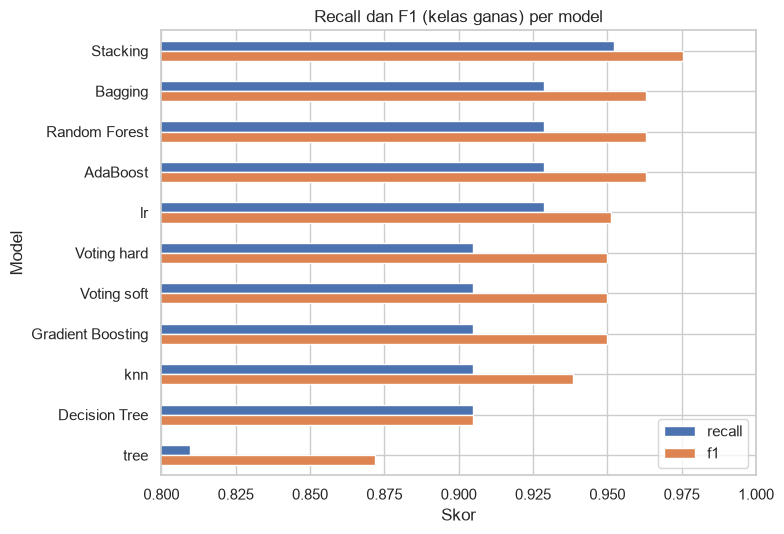

In [72]:
hasil_3 = pd.concat([hasil_vote, hasil_tree.drop(columns="acc_train"),
                     hasil_stack.to_frame("Stacking").T]).sort_values(["recall", "f1"], ascending=False)
display(hasil_3)

hasil_3[["recall", "f1"]].plot.barh(figsize=(8, 5.5), xlim=(0.8, 1.0))
plt.gca().invert_yaxis()
plt.title("Recall dan F1 (kelas ganas) per model")
plt.xlabel("Skor")
plt.ylabel("Model")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

✍️ **Jawaban:**

Urutan teratas berdasarkan recall: Stacking (recall 0.9524, F1 0.9756), Bagging (recall 0.9286, F1 0.9630), Random Forest (recall 0.9286, F1 0.9630), AdaBoost (recall 0.9286, F1 0.9630). Saya merekomendasikan **Stacking** karena recall kelas ganasnya paling tinggi (hanya 2 dari 42 pasien ganas di data test yang terlewat) dengan precision 1.0000 yang tetap tinggi.

Pada skrining kanker, **recall** kelas ganas lebih penting daripada accuracy: false negative berarti pasien kanker
dipulangkan tanpa penanganan, sedangkan false positive "hanya" berujung pemeriksaan lanjutan. Dengan data test 114
pasien (42 ganas), selisih satu pasien = 2.4 poin recall, jadi selisih kecil antar model sebaiknya dikonfirmasi dengan CV.

**h.** **(BONUS)** Tampilkan 10 fitur terpenting Random Forest berdasarkan `feature_importances_` dan berdasarkan
**permutation importance** pada data test (`n_repeats=10`, `random_state=42`) dalam 1 figure 1×2.
✍️ Mengapa hasil keduanya bisa berbeda?

*(BONUS) Show the top 10 Random Forest features by feature_importances_ and by permutation importance on the test set
(1×2 figure). ✍️ Why can the two rankings differ?*

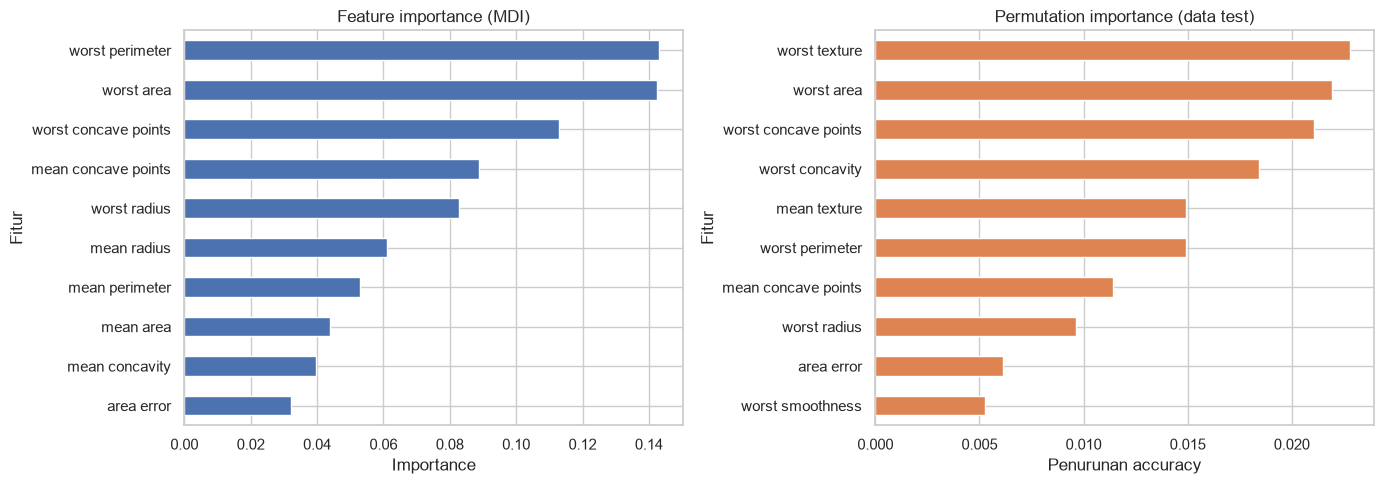

In [75]:
rf_bc = model_tree["Random Forest"]
mdi = pd.Series(rf_bc.feature_importances_, index=bc.feature_names).sort_values(ascending=False).head(10)
perm = permutation_importance(rf_bc, Xb_test, yb_test, n_repeats=10, random_state=42, n_jobs=-1)
perm = pd.Series(perm.importances_mean, index=bc.feature_names).sort_values(ascending=False).head(10)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
mdi[::-1].plot.barh(ax=ax[0], color="#4c72b0")
ax[0].set(title="Feature importance (MDI)", xlabel="Importance", ylabel="Fitur")
perm[::-1].plot.barh(ax=ax[1], color="#dd8452")
ax[1].set(title="Permutation importance (data test)", xlabel="Penurunan accuracy", ylabel="Fitur")
plt.tight_layout()
plt.show()

✍️ **Jawaban:**

Teratas menurut MDI: `worst perimeter`, `worst area`, `worst concave points`; menurut permutation: `worst texture`, `worst area`, `worst concave points`. **MDI** dihitung dari data train (seberapa besar
fitur menurunkan Gini) dan membagi importance di antara fitur yang saling berkorelasi (misalnya `radius`, `perimeter`,
`area`). **Permutation importance** mengukur turunnya accuracy di data test saat satu kolom diacak; jika ada fitur lain
yang membawa informasi serupa, mengacak satu fitur hampir tidak berdampak sehingga nilainya kecil.

---
## SOAL 4 — Teori (10 poin)

Jawab singkat di sel teks di bawah setiap pertanyaan. *Answer briefly in the text cell below each question.*

**1.** Jelaskan perbedaan **bagging** dan **boosting**, beserta contoh model masing-masing.

**Jawaban:** Bagging melatih banyak model **paralel** pada bootstrap sample lalu menggabungkan dengan voting/rata-rata; tujuannya menurunkan **variance** (contoh: `BaggingClassifier`, `RandomForestClassifier`). Boosting melatih model lemah **berurutan**, tiap model fokus pada kesalahan sebelumnya; tujuannya menurunkan **bias** (contoh: `AdaBoostClassifier`, `GradientBoostingClassifier`, XGBoost).

**2.** Mengapa `StandardScaler` dan `SimpleImputer` harus di-*fit* hanya pada data train?

**Jawaban:** Mean, std, dan median adalah informasi dari data. Jika dihitung dengan data test, informasi test bocor ke training (**data leakage**) sehingga skor evaluasi terlalu optimis. Data test harus diperlakukan seperti data baru yang belum pernah dilihat; cukup `transform`, tidak `fit`.

**3.** Apa fungsi `stratify=y` pada `train_test_split`?

**Jawaban:** Menjaga proporsi setiap kelas di data train dan test sama dengan data asli. Tanpa stratify, pada data tidak seimbang test bisa berisi terlalu sedikit (atau terlalu banyak) kelas minoritas sehingga evaluasi tidak stabil.

**4.** Apa pengaruh nilai *k* yang terlalu kecil dan terlalu besar pada KNN?

**Jawaban:** *k* kecil (mis. 1): model mengikuti titik terdekat, sensitif noise → **overfitting** (variance tinggi). *k* besar: voting melibatkan banyak titik jauh, batas keputusan terlalu halus → **underfitting** (bias tinggi). *k* dipilih dengan cross-validation.

**5.** Mengapa Random Forest tidak memerlukan scaling, sedangkan KNN, Regresi Logistik, dan ANN memerlukannya?

**Jawaban:** Pohon keputusan membagi data dengan ambang per fitur (`x <= t`); scaling tidak mengubah urutan nilai sehingga split yang dihasilkan sama. KNN memakai jarak (fitur berskala besar mendominasi), sedangkan Regresi Logistik dan ANN memakai optimasi gradien dan regularisasi yang sensitif terhadap skala.

**6.** Kapan accuracy menyesatkan? Beri contoh kapan *recall* lebih penting dan kapan *precision* lebih penting.

**Jawaban:** Saat kelas tidak seimbang: model yang selalu menebak kelas mayoritas bisa ber-accuracy tinggi tanpa menemukan kelas minoritas. **Recall** penting jika false negative mahal (skrining kanker, deteksi fraud, churn). **Precision** penting jika false positive mahal (filter spam yang membuang email penting, vonis bersalah).

**7.** Jelaskan peran fungsi aktivasi, `alpha`, dan `early_stopping` pada `MLPClassifier`.

**Jawaban:** Fungsi aktivasi (mis. ReLU) membuat jaringan mampu memodelkan hubungan **non-linier**; tanpa aktivasi, banyak layer setara dengan satu model linier. `alpha` adalah regularisasi L2 yang menekan bobot agar tidak overfit. `early_stopping=True` menyisihkan sebagian data train sebagai validasi dan menghentikan training ketika skor validasi berhenti membaik.

**8.** Apa beda *hard voting* dan *soft voting*, dan apa syarat soft voting?

**Jawaban:** Hard voting memilih label terbanyak; soft voting merata-ratakan peluang (`predict_proba`) dan memilih kelas dengan peluang rata-rata tertinggi. Soft voting mensyaratkan semua model dasar punya `predict_proba` dan biasanya lebih akurat karena memakai tingkat keyakinan model.

**9.** Apa itu *OOB score* pada Random Forest?

**Jawaban:** Setiap pohon dilatih pada bootstrap sample, sehingga ±37% data tidak terpilih (*out-of-bag*) untuk pohon itu. Data OOB diprediksi oleh pohon-pohon yang tidak melihatnya, menghasilkan estimasi akurasi seperti validasi tanpa perlu memisahkan data (`oob_score=True`).

**10.** Mengapa hasil koefisien Regresi Logistik baru bisa dibandingkan antar fitur setelah scaling?

**Jawaban:** Besar koefisien bergantung pada satuan fitur: koefisien per 1 rupiah pasti jauh lebih kecil daripada per 1 tahun. Setelah standarisasi, koefisien berarti perubahan log-odds per kenaikan **1 standar deviasi**, sehingga besarnya bisa dibandingkan untuk melihat fitur mana yang paling berpengaruh.